
DATASET OVERVIEW
Rows    : 504
Columns : 5


,new_firm,retail,industry,transport,GINI
0,0.548808,3.771482,105.7,0,0.39
1,0.834373,2.586453,120.3,0,0.35
2,0.432941,2.591177,100.1,0,0.36
3,0.471276,3.805684,103.4,0,0.40
4,2.303000,3.479461,105.1,1,0.34



2. DATA STRUCTURE


,dtype,non_null,missing,missing_%,unique
new_firm,float64,504,0,0.0,504
retail,float64,504,0,0.0,504
industry,float64,504,0,0.0,254
transport,int64,504,0,0.0,2
GINI,float64,504,0,0.0,32



3. DUPLICATES
Duplicate rows: 0

4. COLUMN CLASSIFICATION
Numeric:
['new_firm', 'retail', 'industry', 'transport', 'GINI']

Categorical:
[]

Datetime:
[]

5. NUMERIC SUMMARY


,count,mean,std,min,25%,50%,75%,max,missing,missing_%,skewness,kurtosis
new_firm,504.0,1.533041,1.526393,0.022526,0.748854,1.082965,1.65430,11.004200,0,0.0,3.217430,11.877047
retail,504.0,3.569013,0.522751,2.126123,3.184449,3.592809,3.95818,4.761891,0,0.0,-0.214842,-0.458438
industry,504.0,109.380357,12.811441,73.100000,104.700000,108.500000,113.12500,278.200000,0,0.0,5.299191,63.473241
transport,504.0,0.269841,0.444318,0.000000,0.000000,0.000000,1.00000,1.000000,0,0.0,1.040136,-0.921791
GINI,504.0,0.359306,0.050894,0.200000,0.330000,0.360000,0.38000,0.530000,0,0.0,0.217089,0.552195



6. MISSING VALUES
No missing values.

7. NUMERIC DISTRIBUTIONS


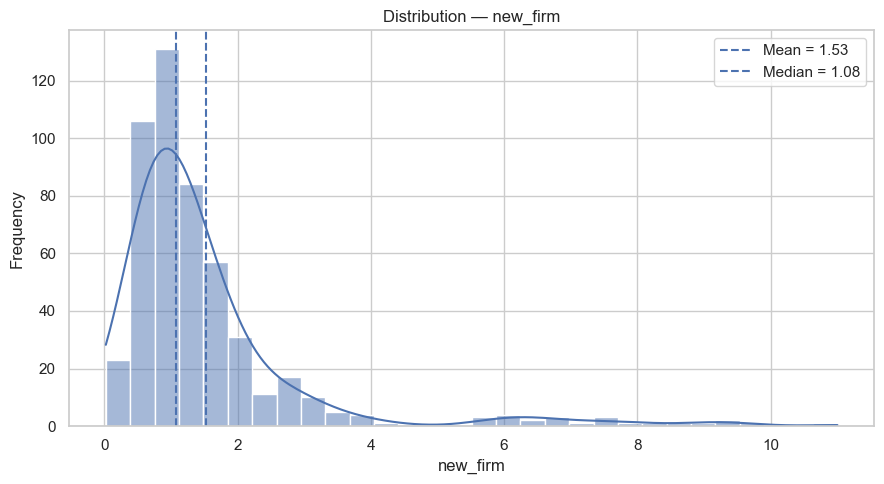

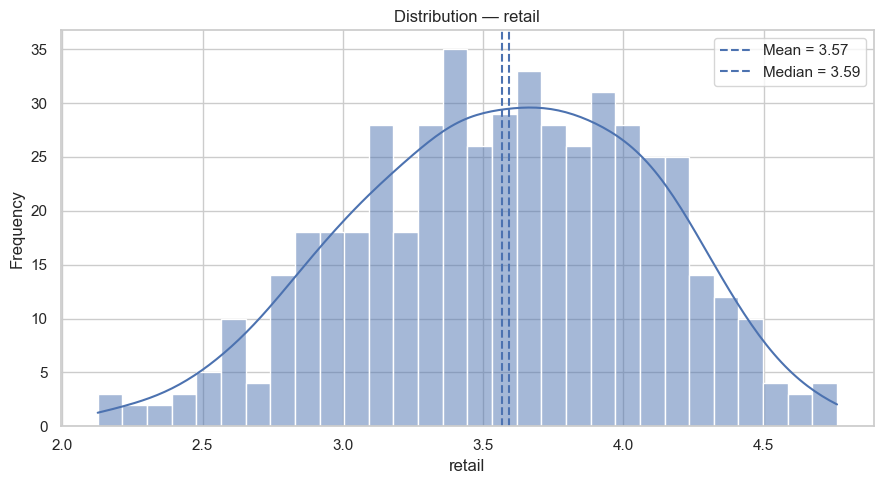

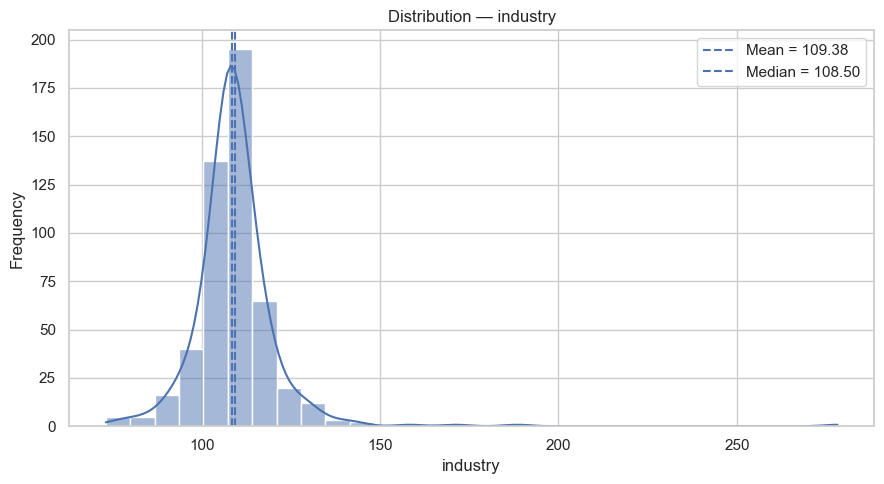

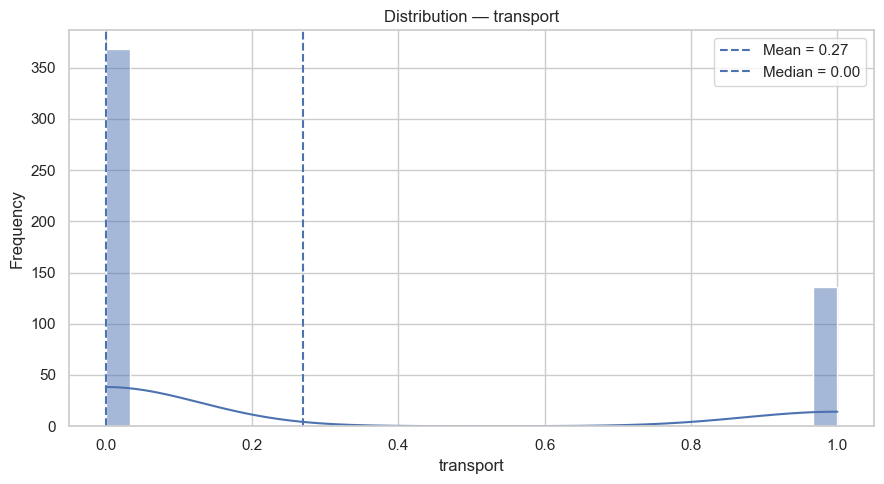

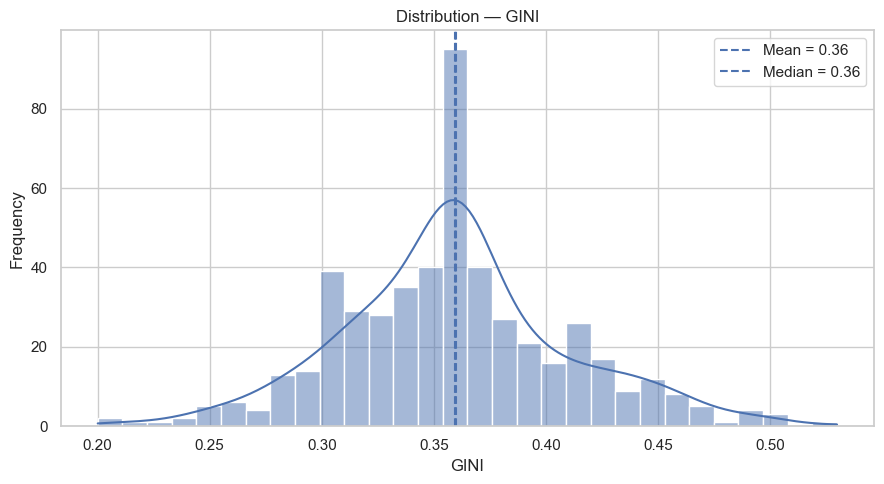


8. BOXPLOTS / OUTLIERS


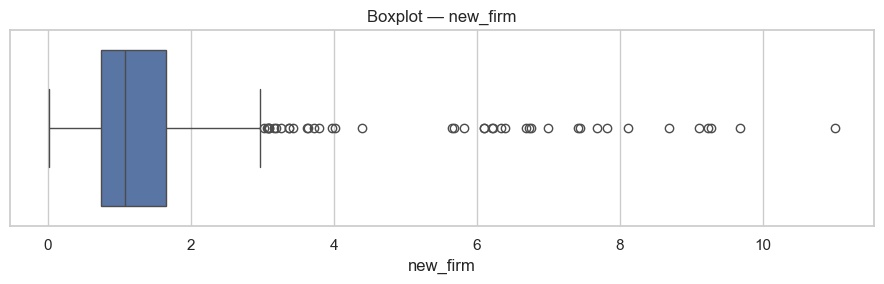

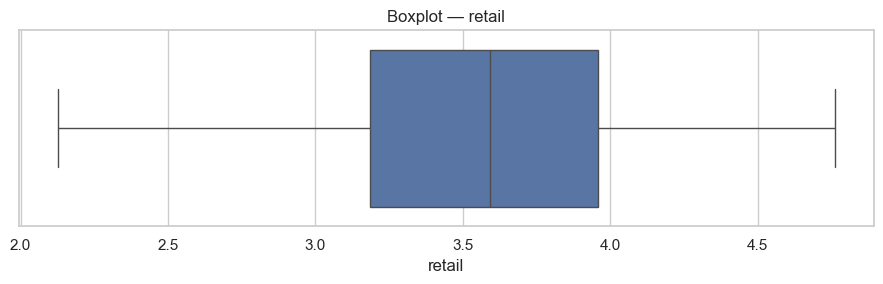

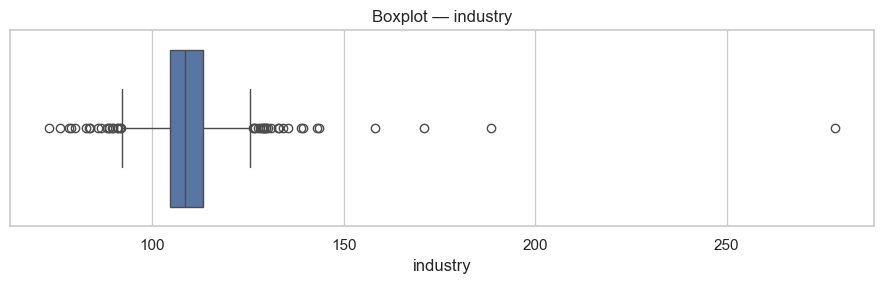

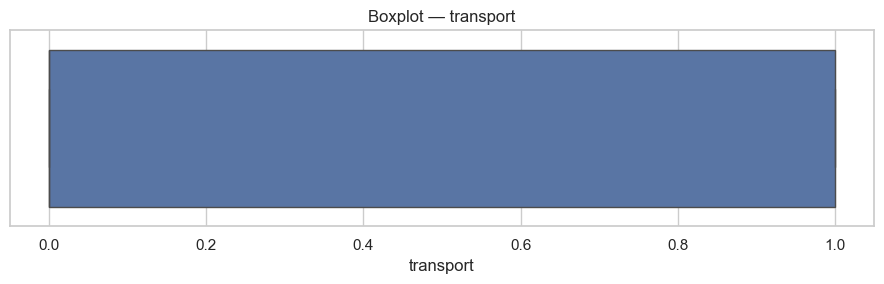

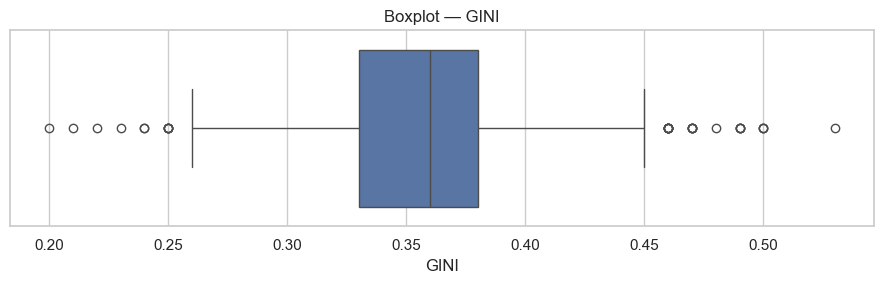


9. CORRELATION MATRIX


,new_firm,retail,industry,transport,GINI
new_firm,1.000,0.529,-0.080,0.428,0.001
retail,0.529,1.000,-0.147,0.286,-0.127
industry,-0.080,-0.147,1.000,-0.021,0.030
transport,0.428,0.286,-0.021,1.000,-0.010
GINI,0.001,-0.127,0.030,-0.010,1.000


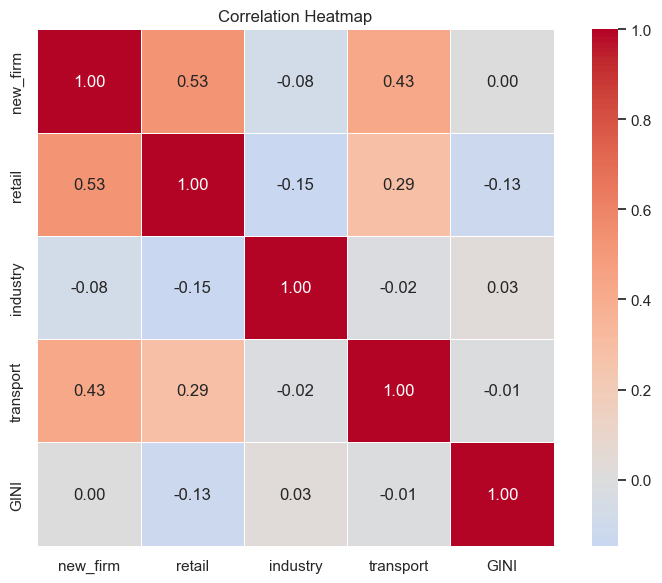


10. STRONGEST CORRELATIONS


correlation
new_firm  retail        0.529338
          transport     0.427743
retail    transport     0.285516
          industry     -0.146930
          GINI         -0.127372
new_firm  industry     -0.080469
industry  GINI          0.029714
          transport    -0.020791
transport GINI         -0.010159
new_firm  GINI          0.001230
          new_firm           NaN
retail    new_firm           NaN
          retail             NaN
industry  new_firm           NaN
          retail             NaN
          industry           NaN
transport new_firm           NaN
          retail             NaN
          industry           NaN
          transport          NaN


11. PAIRPLOT


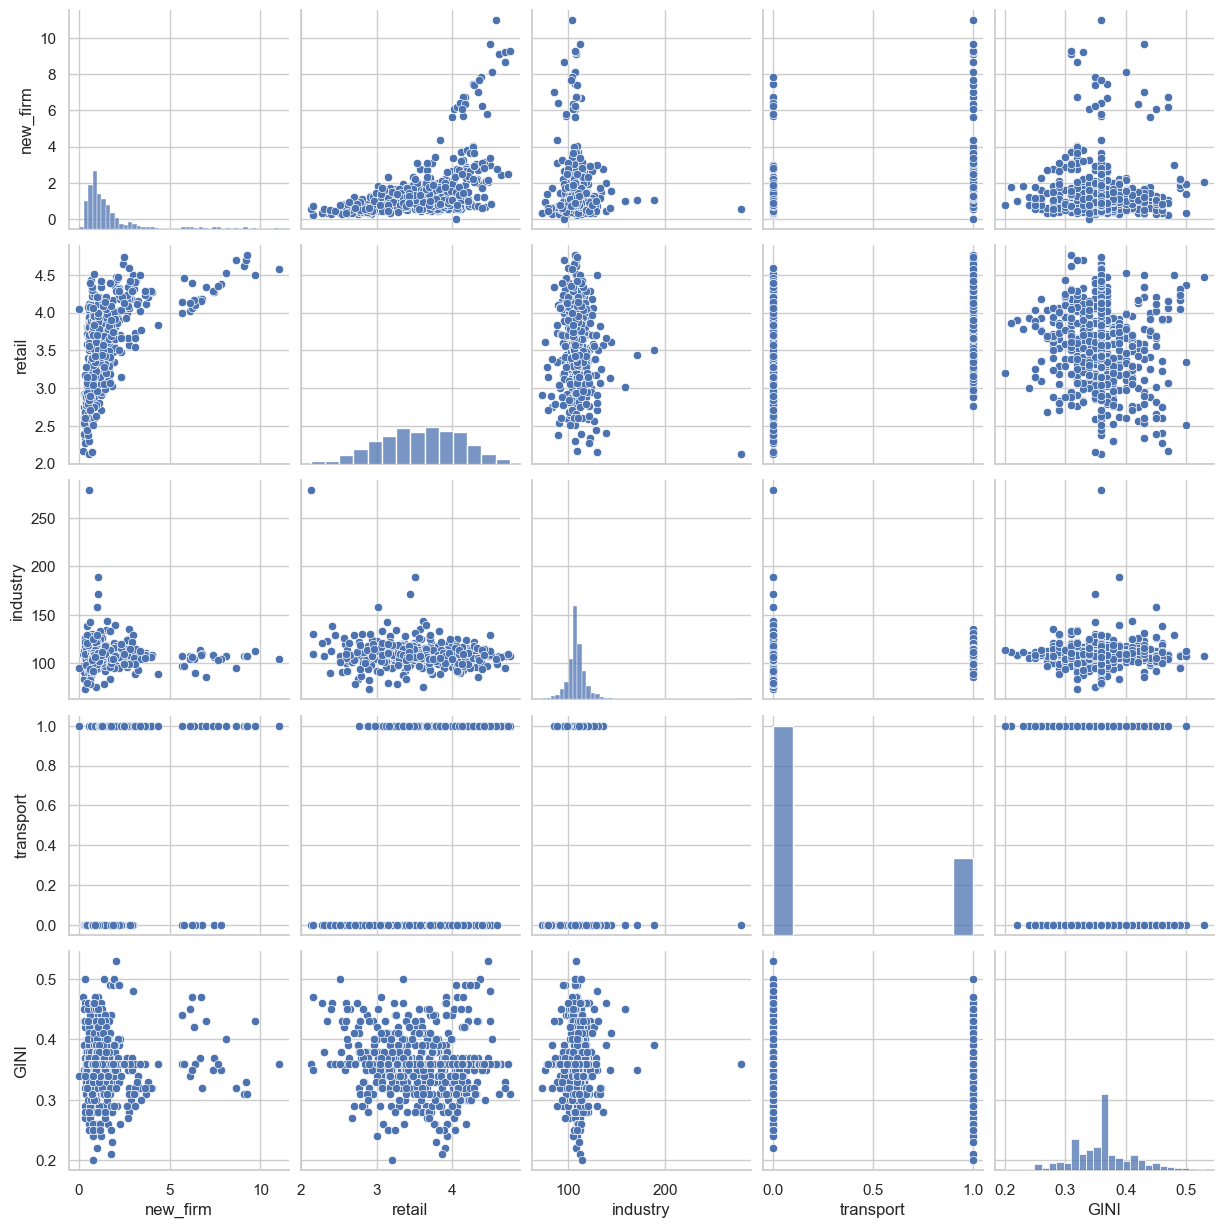


13. OUTLIER SUMMARY — IQR METHOD


,column,Q1,Q3,IQR,lower_bound,upper_bound,outliers,outlier_%
2,industry,104.700,113.125,8.425,92.062,125.762,44,8.730
0,new_firm,0.749,1.654,0.905,-0.609,3.012,42,8.333
4,GINI,0.330,0.380,0.050,0.255,0.455,33,6.548
1,retail,3.184,3.958,0.774,2.024,5.119,0,0.000
3,transport,0.000,1.000,1.000,-1.500,2.500,0,0.000



14. SKEWNESS


,skewness,interpretation
retail,-0.214842,Approximately symmetric / moderate skew
GINI,0.217089,Approximately symmetric / moderate skew
transport,1.040136,Strong right skew
new_firm,3.217430,Strong right skew
industry,5.299191,Strong right skew



15. QUICK SUMMARY
Observations       : 504
Variables          : 5
Numeric variables  : 5
Categorical vars    : 0
Datetime variables  : 0
Missing cells       : 0
Duplicate rows      : 0

EDA complete.


In [5]:
# ============================================================
# QUICK EXCEL EDA
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import skew


# ============================================================
# SETTINGS
# ============================================================

FILE = "data_random.xlsx"
SHEET = 0                 # 0 = first sheet
MAX_CATEGORIES = 15       # categories shown in plots
MAX_PAIRPLOT_COLS = 6     # max variables for pairplot

sns.set_theme(style="whitegrid")


# ============================================================
# 1. LOAD DATA
# ============================================================

df = pd.read_excel(
    FILE,
    sheet_name=SHEET
)

# Remove ID and Year columns
df = df.drop(
    columns=["id", "year"],
    errors="ignore"
)

print("\n" + "=" * 70)
print("DATASET OVERVIEW")
print("=" * 70)

print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]:,}")

display(df.head())


# ============================================================
# 2. DATA TYPES / MISSING / UNIQUE
# ============================================================

print("\n" + "=" * 70)
print("2. DATA STRUCTURE")
print("=" * 70)

info = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_%": df.isna().mean() * 100,
    "unique": df.nunique()
})

display(info)


# ============================================================
# 3. DUPLICATES
# ============================================================

print("\n" + "=" * 70)
print("3. DUPLICATES")
print("=" * 70)

duplicates = df.duplicated().sum()

print(f"Duplicate rows: {duplicates:,}")

if duplicates > 0:
    display(df[df.duplicated(keep=False)].head(20))


# ============================================================
# 4. COLUMN TYPES
# ============================================================

numeric_cols = df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

datetime_cols = df.select_dtypes(
    include=["datetime"]
).columns.tolist()

print("\n" + "=" * 70)
print("4. COLUMN CLASSIFICATION")
print("=" * 70)

print("Numeric:")
print(numeric_cols)

print("\nCategorical:")
print(categorical_cols)

print("\nDatetime:")
print(datetime_cols)


# ============================================================
# 5. NUMERIC DESCRIPTIVE STATISTICS
# ============================================================

if numeric_cols:

    print("\n" + "=" * 70)
    print("5. NUMERIC SUMMARY")
    print("=" * 70)

    summary = df[numeric_cols].describe().T

    summary["missing"] = df[numeric_cols].isna().sum()
    summary["missing_%"] = (
        df[numeric_cols].isna().mean() * 100
    )

    summary["skewness"] = df[numeric_cols].skew()
    summary["kurtosis"] = df[numeric_cols].kurtosis()

    display(summary)


# ============================================================
# 6. MISSING VALUES
# ============================================================

missing = (
    df.isna()
      .sum()
      .sort_values(ascending=False)
)

missing = missing[missing > 0]

print("\n" + "=" * 70)
print("6. MISSING VALUES")
print("=" * 70)

if len(missing) == 0:

    print("No missing values.")

else:

    display(
        pd.DataFrame({
            "missing": missing,
            "missing_%": (
                missing / len(df) * 100
            ).round(2)
        })
    )

    plt.figure(figsize=(10, 5))

    sns.barplot(
        x=missing.values,
        y=missing.index
    )

    plt.title("Missing Values by Column")
    plt.xlabel("Number Missing")
    plt.ylabel("Column")

    plt.tight_layout()
    plt.show()


# ============================================================
# 7. HISTOGRAM + KDE
# ============================================================

if numeric_cols:

    print("\n" + "=" * 70)
    print("7. NUMERIC DISTRIBUTIONS")
    print("=" * 70)

    for col in numeric_cols:

        plt.figure(figsize=(9, 5))

        sns.histplot(
            df[col].dropna(),
            bins=30,
            kde=True
        )

        plt.axvline(
            df[col].mean(),
            linestyle="--",
            label=f"Mean = {df[col].mean():.2f}"
        )

        plt.axvline(
            df[col].median(),
            linestyle="--",
            label=f"Median = {df[col].median():.2f}"
        )

        plt.title(f"Distribution — {col}")
        plt.xlabel(col)
        plt.ylabel("Frequency")
        plt.legend()

        plt.tight_layout()
        plt.show()


# ============================================================
# 8. BOXPLOTS
# ============================================================

if numeric_cols:

    print("\n" + "=" * 70)
    print("8. BOXPLOTS / OUTLIERS")
    print("=" * 70)

    for col in numeric_cols:

        plt.figure(figsize=(9, 3))

        sns.boxplot(
            x=df[col]
        )

        plt.title(f"Boxplot — {col}")
        plt.xlabel(col)

        plt.tight_layout()
        plt.show()


# ============================================================
# 9. CORRELATION MATRIX
# ============================================================

if len(numeric_cols) >= 2:

    print("\n" + "=" * 70)
    print("9. CORRELATION MATRIX")
    print("=" * 70)

    corr = df[numeric_cols].corr()

    display(corr.round(3))


# ============================================================
# 10. CORRELATION HEATMAP
# ============================================================

if len(numeric_cols) >= 2:

    plt.figure(
        figsize=(
            max(8, len(numeric_cols) * 0.8),
            max(6, len(numeric_cols) * 0.7)
        )
    )

    sns.heatmap(
        corr,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        square=True,
        linewidths=0.5
    )

    plt.title("Correlation Heatmap")

    plt.tight_layout()
    plt.show()


# ============================================================
# 11. STRONGEST CORRELATIONS
# ============================================================

if len(numeric_cols) >= 2:

    print("\n" + "=" * 70)
    print("10. STRONGEST CORRELATIONS")
    print("=" * 70)

    corr_pairs = (
        corr.where(
            np.triu(
                np.ones(corr.shape),
                k=1
            ).astype(bool)
        )
        .stack()
        .sort_values(
            key=abs,
            ascending=False
        )
    )

    display(
        corr_pairs
        .head(20)
        .rename("correlation")
        .to_frame()
    )


# ============================================================
# 12. PAIRPLOT
# ============================================================

if len(numeric_cols) >= 2:

    print("\n" + "=" * 70)
    print("11. PAIRPLOT")
    print("=" * 70)

    pair_cols = numeric_cols[:MAX_PAIRPLOT_COLS]

    sns.pairplot(
        df[pair_cols].dropna()
    )

    plt.show()


# ============================================================
# 13. CATEGORICAL VARIABLES
# ============================================================

if categorical_cols:

    print("\n" + "=" * 70)
    print("12. CATEGORICAL VARIABLES")
    print("=" * 70)

    for col in categorical_cols:

        print(f"\n--- {col} ---")

        counts = (
            df[col]
            .value_counts(dropna=False)
        )

        display(
            counts
            .head(MAX_CATEGORIES)
            .to_frame("count")
        )

        plot_counts = (
            df[col]
            .value_counts()
            .head(MAX_CATEGORIES)
        )

        if len(plot_counts) > 0:

            plt.figure(figsize=(9, 5))

            sns.barplot(
                x=plot_counts.values,
                y=plot_counts.index
            )

            plt.title(
                f"Top Categories — {col}"
            )

            plt.xlabel("Count")
            plt.ylabel(col)

            plt.tight_layout()
            plt.show()


# ============================================================
# 14. OUTLIER DETECTION — IQR
# ============================================================

if numeric_cols:

    print("\n" + "=" * 70)
    print("13. OUTLIER SUMMARY — IQR METHOD")
    print("=" * 70)

    outlier_results = []

    for col in numeric_cols:

        x = df[col].dropna()

        Q1 = x.quantile(0.25)
        Q3 = x.quantile(0.75)

        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        outliers = (
            (x < lower) |
            (x > upper)
        )

        n_outliers = outliers.sum()

        outlier_results.append({
            "column": col,
            "Q1": Q1,
            "Q3": Q3,
            "IQR": IQR,
            "lower_bound": lower,
            "upper_bound": upper,
            "outliers": n_outliers,
            "outlier_%": (
                n_outliers / len(x) * 100
            )
        })

    outlier_df = pd.DataFrame(
        outlier_results
    )

    display(
        outlier_df
        .sort_values(
            "outlier_%",
            ascending=False
        )
        .round(3)
    )


# ============================================================
# 15. SKEWNESS
# ============================================================

if numeric_cols:

    print("\n" + "=" * 70)
    print("14. SKEWNESS")
    print("=" * 70)

    skew_df = pd.DataFrame({
        "skewness": df[numeric_cols].skew()
    })

    skew_df["interpretation"] = np.select(
        [
            skew_df["skewness"] < -1,
            skew_df["skewness"] > 1,
            skew_df["skewness"].abs() <= 1
        ],
        [
            "Strong left skew",
            "Strong right skew",
            "Approximately symmetric / moderate skew"
        ],
        default="Moderate skew"
    )

    display(
        skew_df.sort_values(
            "skewness"
        )
    )


# ============================================================
# 16. FINAL QUICK SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("15. QUICK SUMMARY")
print("=" * 70)

print(f"Observations       : {len(df):,}")
print(f"Variables          : {len(df.columns):,}")
print(f"Numeric variables  : {len(numeric_cols):,}")
print(f"Categorical vars    : {len(categorical_cols):,}")
print(f"Datetime variables  : {len(datetime_cols):,}")
print(f"Missing cells       : {df.isna().sum().sum():,}")
print(f"Duplicate rows      : {df.duplicated().sum():,}")

print("\nEDA complete.")